In [1]:
import os, re, numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [4]:
import urllib.request
import zipfile
import io

if os.path.exists("SMSSpamCollection"):
    df = pd.read_csv("SMSSpamCollection", sep="\t", header=None,
                     names=["label", "message"], encoding="latin-1", quoting=3)
else:
    print("Downloading SMS Spam Collection dataset from UCI...")
    url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
    try:
        # Download and extract zip archive in memory
        with urllib.request.urlopen(url) as response:
            zip_file = zipfile.ZipFile(io.BytesIO(response.read()))
            # Extract SMSSpamCollection
            with zip_file.open("SMSSpamCollection") as f:
                df = pd.read_csv(f, sep="\t", header=None,
                                 names=["label", "message"], encoding="latin-1", quoting=3)
    except Exception as e:
        print("UCI download failed, attempting backup public mirror...")
        # Fallback public mirror raw dataset URL
        backup_url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
        df = pd.read_csv(backup_url, sep="\t", header=None,
                         names=["label", "message"], skiprows=1, encoding="latin-1")

print("Messages loaded:", len(df))
print("Missing values:\n", df.isnull().sum())
df = df.dropna()
before = len(df)
df = df.drop_duplicates(subset="message").reset_index(drop=True)
print("Duplicates removed:", before - len(df))
print("Messages after cleaning (N):", len(df))
df["label"] = df["label"].str.strip().str.lower().map({"spam": 1, "ham": 0})

Messages loaded: 5574
Missing values:
 label      0
message    0
dtype: int64
Duplicates removed: 403
Messages after cleaning (N): 5171


Spam messages: 653   Ham messages: 4518   Total: 5171
P(Spam) = 0.1263
P(Ham)  = 0.8737


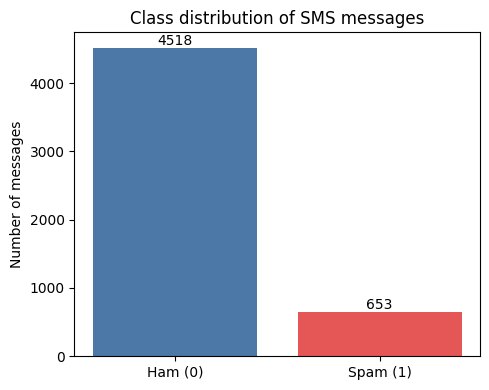

In [5]:
N = len(df)
n_spam = int((df["label"] == 1).sum())
n_ham = int((df["label"] == 0).sum())
p_spam, p_ham = n_spam / N, n_ham / N
print(f"Spam messages: {n_spam}   Ham messages: {n_ham}   Total: {N}")
print(f"P(Spam) = {p_spam:.4f}")
print(f"P(Ham)  = {p_ham:.4f}")

plt.figure(figsize=(5, 4))
plt.bar(["Ham (0)", "Spam (1)"], [n_ham, n_spam], color=["#4C78A8", "#E45756"])
for i, v in enumerate([n_ham, n_spam]):
    plt.text(i, v + 40, str(v), ha="center")
plt.title("Class distribution of SMS messages")
plt.ylabel("Number of messages")
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150)
plt.show()

In [6]:
def contains_word(text, word):
    return re.search(rf"\b{re.escape(word)}\b", text.lower()) is not None

rows = []
for w in ["free", "prize", "win", "urgent", "offer"]:
    has_w = df["message"].apply(lambda t: contains_word(t, w))
    n_w = int(has_w.sum())
    n_w_spam = int((has_w & (df["label"] == 1)).sum())
    p_direct = n_w_spam / n_w
    p_w_given_spam = n_w_spam / n_spam
    p_w = n_w / N
    p_bayes = p_w_given_spam * p_spam / p_w
    rows.append([w, n_w, n_w_spam, p_direct, p_w_given_spam, p_w, p_bayes])

word_table = pd.DataFrame(rows, columns=["word", "msgs_with_word", "spam_with_word",
    "P(Spam|word) direct", "P(word|Spam)", "P(word)", "P(Spam|word) Bayes"])
print(word_table.round(4).to_string(index=False))
print("Direct and Bayes values agree:",
      np.allclose(word_table["P(Spam|word) direct"], word_table["P(Spam|word) Bayes"]))

  word  msgs_with_word  spam_with_word  P(Spam|word) direct  P(word|Spam)  P(word)  P(Spam|word) Bayes
  free             203             148               0.7291        0.2266   0.0393              0.7291
 prize              73              73               1.0000        0.1118   0.0141              1.0000
   win              55              49               0.8909        0.0750   0.0106              0.8909
urgent              62              57               0.9194        0.0873   0.0120              0.9194
 offer              30              24               0.8000        0.0368   0.0058              0.8000
Direct and Bayes values agree: True


In [7]:
Y = df["label"].values
E_Y = p_spam
Var_Y = p_spam * (1 - p_spam)
print(f"E(Y)   = P(Spam)   = {E_Y:.4f}")
print(f"Var(Y) = p(1 - p)  = {Var_Y:.4f}")
print(f"Check with numpy: mean = {Y.mean():.4f}, variance = {Y.var():.4f}")

E(Y)   = P(Spam)   = 0.1263
Var(Y) = p(1 - p)  = 0.1103
Check with numpy: mean = 0.1263, variance = 0.1103


In [8]:
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df["message"], df["label"], test_size=0.20, stratify=df["label"], random_state=42)
vectorizer = CountVectorizer()
X_train = vectorizer.fit_transform(X_train_txt)
X_test = vectorizer.transform(X_test_txt)
print("Train:", X_train.shape, "  Test:", X_test.shape)
print(f"Spam share  full: {df['label'].mean():.4f}  train: {y_train.mean():.4f}  test: {y_test.mean():.4f}")

Train: (4136, 7698)   Test: (1035, 7698)
Spam share  full: 0.1263  train: 0.1262  test: 0.1266


In [9]:
model = MultinomialNB()
model.fit(X_train, y_train)
joblib.dump(model, "spam_nb_model.pkl")
joblib.dump(vectorizer, "count_vectorizer.pkl")
print("Model trained and saved")

Model trained and saved


Accuracy: 0.9816
              precision    recall  f1-score   support

         Ham     0.9857    0.9934    0.9895       904
        Spam     0.9516    0.9008    0.9255       131

    accuracy                         0.9816      1035
   macro avg     0.9687    0.9471    0.9575      1035
weighted avg     0.9814    0.9816    0.9814      1035

Confusion matrix [[TN FP], [FN TP]]:
 [[898   6]
 [ 13 118]]
Spam classified as genuine (false negatives): 13
Genuine classified as spam (false positives): 6


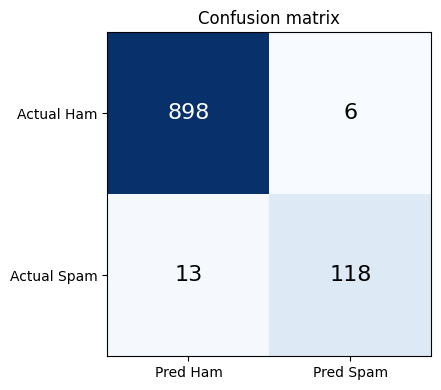

In [10]:
y_pred = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=["Ham", "Spam"], digits=4))
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print("Confusion matrix [[TN FP], [FN TP]]:\n", cm)
print("Spam classified as genuine (false negatives):", fn)
print("Genuine classified as spam (false positives):", fp)

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred Ham", "Pred Spam"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual Ham", "Actual Spam"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=16,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_title("Confusion matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [12]:
def predict_sms(message):
    probs = model.predict_proba(vectorizer.transform([message]))[0]
    label = "Spam" if probs[1] >= 0.5 else "Ham"
    print(f"SMS: {message}")
    print(f"Prediction: {label}")
    print(f"P(Spam | Message) = {probs[1]:.2f}")
    print(f"P(Ham | Message) = {probs[0]:.2f}\n")

predict_sms("Congratulations! You have won a free prize. Claim now.")
predict_sms("URGENT! Your mobile number has been selected for a 2000 cash prize. Call now to claim")
predict_sms("Hey, are we meeting at 5 for lunch?")

while True:
    try:
        msg = input("Enter an SMS (empty line to stop): ").strip()
    except Exception:
        break
    if not msg:
        break
    predict_sms(msg)

SMS: Congratulations! You have won a free prize. Claim now.
Prediction: Spam
P(Spam | Message) = 1.00
P(Ham | Message) = 0.00

SMS: URGENT! Your mobile number has been selected for a 2000 cash prize. Call now to claim
Prediction: Spam
P(Spam | Message) = 1.00
P(Ham | Message) = 0.00

SMS: Hey, are we meeting at 5 for lunch?
Prediction: Ham
P(Spam | Message) = 0.00
P(Ham | Message) = 1.00

Enter an SMS (empty line to stop): 
